# 3D. LSTM Autoencoder - NASA Turbofan Engines
Train AE on first-20-cycles-per-engine (treated as healthy) sensor data.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import MinMaxScaler

In [2]:
df = pd.read_csv("../datasets/AutoEncoder/NASA Turbofan ENgine/NASA TurboFan Engine.csv")

# simple heuristic: first 20 cycles of each engine are healthy, rest = possibly faulty
y = (df["cycle"] > 20).astype(int).to_numpy()

# features: everything except unit + cycle columns
x = df.drop(columns=["unit", "cycle"]).to_numpy().astype("float32")

scaler = MinMaxScaler()
x = scaler.fit_transform(x)

# sliding windows (W=15)
W = 15
Xw = []
yw = []
for i in range(len(x) - W + 1):
    Xw.append(x[i:i+W])
    yw.append(y[i:i+W].max())
Xw = np.array(Xw)
yw = np.array(yw)

Xw_norm = Xw[yw == 0]
print("windows:", Xw.shape, "healthy:", Xw_norm.shape)

windows: (20617, 15, 26) healthy: (600, 15, 26)


In [3]:
model = keras.Sequential([
    layers.Input(shape=(15, Xw.shape[2])),
    layers.LSTM(32, activation="relu"),
    layers.RepeatVector(15),
    layers.LSTM(32, activation="relu", return_sequences=True),
    layers.TimeDistributed(layers.Dense(Xw.shape[2])),
])
model.compile(optimizer="adam", loss="mse")
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         7,552 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector (RepeatVector)    │ (None, 15, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 15, 32)         │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 15, 26)         │           858 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,730 (65.35 KB)

 Trainable params: 16,730 (65.35 KB)

 Non-trainable params: 0 (0.00 B)

In [4]:
history = model.fit(Xw_norm, Xw_norm, epochs=5, validation_split=0.1)

Epoch 1/5
17/17 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - loss: 0.1539 - val_loss: 0.1129
Epoch 2/5
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0793 - val_loss: 0.0535
Epoch 3/5
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0396 - val_loss: 0.0280
Epoch 4/5
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0234 - val_loss: 0.0188
Epoch 5/5
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0169 - val_loss: 0.0148


In [5]:
recon = model.predict(Xw)
err = np.mean((Xw - recon) ** 2, axis=(1, 2))

threshold = np.quantile(err[yw == 0], 0.95)
y_pred = (err > threshold).astype(int)

print(f"flagged faulty: {y_pred.sum()}  actual non-healthy: {yw.sum()}")
print(f"threshold: {threshold:.6f}")

flagged faulty: 7384  actual non-healthy: 20017
threshold: 0.021951


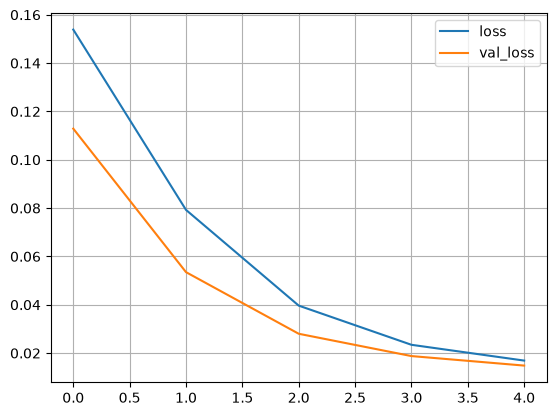

In [6]:
for k, v in history.history.items():
    plt.plot(v, label=k)
plt.legend()
plt.grid()
plt.show()